Utterances: 20000 Train/Dev/Test: 16000 2000 2000
Training tokens: 108704 Types: 55
Top 15: [('to', 7495), ('the', 7353), ('bus', 5324), ('is', 5308), ('from', 4279), ('at', 4205), ('a', 3221), ('i', 3209), ('my', 3189), ('ticket', 3183), ('madurai', 2746), ('salem', 2666), ('trichy', 2664), ('vellore', 2661), ('chennai', 2659)]
threshold 1 vocab 55 train tokens mapped UNK % 0.0
threshold 2 vocab 55 train tokens mapped UNK % 0.0
threshold 3 vocab 55 train tokens mapped UNK % 0.0
threshold 5 vocab 55 train tokens mapped UNK % 0.0
Development OOV rate %: 0.0
Unigrams: 57 Bigrams: 122 Trigrams: 216
Bigram cross-entropy bits/token: 1.5438
Bigram perplexity: 2.9157
Add-k 1.0 perplexity 2.978
Add-k 0.1 perplexity 2.9157
Add-k 0.01 perplexity 2.9094


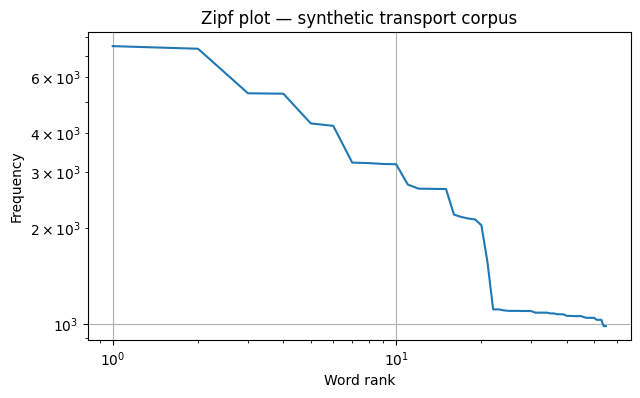

Uniform distribution entropy: 2.0
Peaked distribution entropy: 0.847584679824574
Example distribution entropy: 1.7427376486136672
HMM example: [('please', 'INTJ'), ('book', 'VERB'), ('two', 'PRON'), ('tickets', 'NOUN'), ('to', 'ADP'), ('vellore', 'PROPN'), ('at', 'ADP')]
Rescored hypotheses:
-18.9806 two tickets to Vellore
-20.0776 two ticket to Vellore
-26.1805 to tickets to Vellore
-31.9574 two tickets to Velore
-35.5655 two tickets for Vellore
Example WER: 0.25
Saved train/dev/test text files.


In [1]:
import random, re, math, time, sys
from collections import Counter, defaultdict
random.seed(42)

# CELL 2 — Generate a documented synthetic transport corpus
origins = ["Chennai", "Vellore", "Madurai", "Salem", "Trichy", "Coimbatore"]
destinations = ["Vellore", "Madurai", "Salem", "Trichy", "Chennai", "Erode"]
times = ["6:30", "7:15", "8:00", "9:45", "12:30", "18:00"]
templates = [
    "what time is the bus from {o} to {d}",
    "please book {n} tickets to {d}",
    "is there a train from {o} to {d}",
    "how much is the fare from {o} to {d}",
    "when does the bus leave {o}",
    "show me the next bus at {t}",
    "cancel my ticket to {d}",
    "i want a return ticket from {o} to {d}",
    "is the train delayed at {o}",
    "where is the bus stand in {d}",
    "please confirm platform number {n}",
    "i need to change my travel date",
    "does this bus stop at {d}",
    "can i get a refund for my ticket",
    "tell me the arrival time at {d}"
]
def make_utterance():
    s = random.choice(templates).format(
        o=random.choice(origins), d=random.choice(destinations),
        n=random.choice(["1","2","3","4"]), t=random.choice(times))
    return s.lower()

corpus = [make_utterance() for _ in range(20000)]
random.shuffle(corpus)
n = len(corpus)
train = corpus[:int(.8*n)]
dev = corpus[int(.8*n):int(.9*n)]
test = corpus[int(.9*n):]

def tokenize(s):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\\d+:\\d+|\\d+", s.lower())

train_tokens = [tokenize(s) for s in train]
dev_tokens = [tokenize(s) for s in dev]
test_tokens = [tokenize(s) for s in test]
flat = [w for sent in train_tokens for w in sent]
freq = Counter(flat)
print("Utterances:", len(corpus), "Train/Dev/Test:",len(train),len(dev),len(test))
print("Training tokens:",len(flat),"Types:",len(freq))
print("Top 15:",freq.most_common(15))

# CELL 3 — Vocabulary thresholds, UNK and OOV
for threshold in [1,2,3,5]:
    vocab = {w for w,c in freq.items() if c >= threshold}
    rare = sum(c for w,c in freq.items() if c < threshold)
    print("threshold",threshold,"vocab",len(vocab),
          "train tokens mapped UNK %",round(100*rare/max(1,len(flat)),3))
vocab = {w for w,c in freq.items() if c >= 2}
def unk_sent(sent):
    return [w if w in vocab else "<UNK>" for w in sent]
train_u = [unk_sent(s) for s in train_tokens]
dev_u = [unk_sent(s) for s in dev_tokens]
test_u = [unk_sent(s) for s in test_tokens]
dev_oov = sum(w not in vocab for s in dev_tokens for w in s)
dev_total = sum(map(len,dev_tokens))
print("Development OOV rate %:",100*dev_oov/max(1,dev_total))

# CELL 4 — N-gram counts with sentence boundaries
uni, bi, tri = Counter(), Counter(), Counter()
ctx1, ctx2 = Counter(), Counter()
for sent in train_u:
    x = ["<s>","<s>"] + sent + ["</s>"]
    uni.update(x)
    for i in range(1,len(x)):
        bi[(x[i-1],x[i])] += 1
        ctx1[x[i-1]] += 1
    for i in range(2,len(x)):
        tri[(x[i-2],x[i-1],x[i])] += 1
        ctx2[(x[i-2],x[i-1])] += 1
V = len(vocab) + 1
print("Unigrams:",len(uni),"Bigrams:",len(bi),"Trigrams:",len(tri))

# CELL 5 — Sentence probability and smoothed bigram perplexity
def p_uni(w):
    return (uni[w]+1)/(sum(uni.values())+V)
def p_bi(w, h, k=0.1):
    return (bi[(h,w)]+k)/(ctx1[h]+k*V)
def p_tri(w,h2,h1,k=0.1):
    return (tri[(h2,h1,w)]+k)/(ctx2[(h2,h1)]+k*V)
def cross_entropy_bigram(data, k=0.1):
    loss=0; count=0
    for sent in data:
        x=["<s>"]+sent+["</s>"]
        for i in range(1,len(x)):
            loss -= math.log2(p_bi(x[i],x[i-1],k))
            count += 1
    return loss/max(1,count)
ce = cross_entropy_bigram(dev_u)
print("Bigram cross-entropy bits/token:",round(ce,4))
print("Bigram perplexity:",round(2**ce,4))
for k in [1.0,0.1,0.01]:
    ce_k=cross_entropy_bigram(dev_u,k)
    print("Add-k",k,"perplexity",round(2**ce_k,4))

# CELL 6 — Zipf data (plot)
import matplotlib.pyplot as plt
rank_freq = sorted(freq.values(), reverse=True)
plt.figure(figsize=(7,4))
plt.loglog(range(1,len(rank_freq)+1),rank_freq)
plt.xlabel("Word rank"); plt.ylabel("Frequency")
plt.title("Zipf plot — synthetic transport corpus")
plt.grid(True); plt.show()

# CELL 7 — Entropy examples
def entropy(probs):
    return -sum(p*math.log2(p) for p in probs if p>0)
print("Uniform distribution entropy:",entropy([.25,.25,.25,.25]))
print("Peaked distribution entropy:",entropy([.85,.05,.05,.05]))
print("Example distribution entropy:",entropy([.5,.25,.15,.10]))

# CELL 8 — Simple HMM POS tagger demonstration
# This illustrative tagger uses transparent lexical/context rules to create
# demonstration labels. For assessment-quality results, replace with human tags.
def tag_word(w, prev_word=""):
    if w in {"what","when","where","how","who","does","is","can","i","my","me","this"}:
        return "PRON" if w in {"i","my","me","this"} else "AUX"
    if w in {"the","a","an","next","my"}: return "DET"
    if w in {"from","to","at","in","for","of"}: return "ADP"
    if w in {"and","or"}: return "CONJ"
    if w in {"please"}: return "INTJ"
    if re.fullmatch(r"\\d+:\\d+",w): return "TIME"
    if w.isdigit(): return "NUM"
    if w in {x.lower() for x in origins+destinations}: return "PROPN"
    if w.endswith("ly"): return "ADV"
    if w in {"book","cancel","change","confirm","show","tell","get","stop","leave","need","want","refund"}:
        return "VERB"
    if w in {"bus","train","ticket","fare","stand","time","arrival","platform","number","date"}:
        return "NOUN"
    return "NOUN"

tagged = [[(w,tag_word(w)) for w in s] for s in train_u]
trans, emit, tag_counts = Counter(), Counter(), Counter()
for sent in tagged:
    tags=["<BOS>"]+[t for w,t in sent]+["<EOS>"]
    for a,b in zip(tags,tags[1:]): trans[(a,b)] += 1
    for w,t in sent: emit[(t,w)] += 1; tag_counts[t] += 1
tags = sorted(tag_counts)
def hmm_viterbi(words):
    # Demonstration Viterbi using emission candidates learned from labelled training
    states=tags
    dp=[]; back=[]
    for i,w in enumerate(words):
        scores={}; ptr={}
        for t in states:
            e=(emit[(t,w)]+0.1)/(tag_counts[t]+0.1*(len(vocab)+1))
            if i==0:
                scores[t]=math.log((trans[("<BOS>",t)]+0.1)/(sum(trans[("<BOS>",x)] for x in states)+0.1*len(states)))+math.log(e)
                ptr[t]=None
            else:
                candidates=[]
                for prev in states:
                    a=(trans[(prev,t)]+0.1)/(sum(trans[(prev,x)] for x in states)+0.1*len(states))
                    candidates.append((dp[-1][prev]+math.log(a)+math.log(e),prev))
                scores[t],ptr[t]=max(candidates)
        dp.append(scores); back.append(ptr)
    last=max(states,key=lambda t:dp[-1][t])
    seq=[last]
    for i in range(len(words)-1,0,-1): seq.append(back[i][seq[-1]])
    return list(reversed(seq))
example=tokenize("please book two tickets to Vellore at 6:30")
print("HMM example:",list(zip(example,hmm_viterbi(example))))

# CELL 9 — Candidate hypothesis rescoring demonstration
def lm_score(sentence):
    words=unk_sent(tokenize(sentence))
    x=["<s>"]+words+["</s>"]
    return sum(math.log(p_bi(x[i],x[i-1],0.1)) for i in range(1,len(x)))
hypotheses=[
    "two tickets to Vellore",
    "to tickets to Vellore",
    "two tickets to Velore",
    "two ticket to Vellore",
    "two tickets for Vellore"
]
print("Rescored hypotheses:")
for h in sorted(hypotheses,key=lm_score,reverse=True):
    print(round(lm_score(h),4),h)

# CELL 10 — WER utility (requires reference and selected hypothesis)
def edit_distance(ref, hyp):
    r=tokenize(ref); h=tokenize(hyp)
    d=[[0]*(len(h)+1) for _ in range(len(r)+1)]
    for i in range(len(r)+1): d[i][0]=i
    for j in range(len(h)+1): d[0][j]=j
    for i in range(1,len(r)+1):
        for j in range(1,len(h)+1):
            cost=0 if r[i-1]==h[j-1] else 1
            d[i][j]=min(d[i-1][j]+1,d[i][j-1]+1,d[i-1][j-1]+cost)
    return d[-1][-1]/max(1,len(r))
print("Example WER:",edit_distance("two tickets to Vellore","two tickets for Vellore"))

# CELL 11 — Save corpus files for evidence
with open("transport_train.txt","w") as f:
    f.write("\\n".join(train))
with open("transport_dev.txt","w") as f:
    f.write("\\n".join(dev))
with open("transport_test.txt","w") as f:
    f.write("\\n".join(test))
print("Saved train/dev/test text files.")
